# 04 — A rule-based state machine

**Goal:** decide *fall* or *no fall* for every video **without any machine learning**, only with simple rules on the skeleton, read frame after frame like a human watching the video.

**Idea:** a fall is a **sequence of events**, not a single picture:
1. the person is upright (standing, walking, sitting);
2. the hips **drop fast** → *falling*;
3. soon after, the body is **flat or on the floor** → *lying*;
4. the person **stays** down → *fall detected*.

A **state machine** encodes exactly this: the system is always in one *state*, and rules say when it moves to the next one.

```
NORMAL ──(hips drop fast)──▶ FALLING ──(body flat / hips on floor)──▶ LYING ──(still lying ⅓ s later)──▶ FALL DETECTED
   ▲                            │                                       │
   └────(nothing within 1.5 s)──┘                                       │
   └──────────────────────────(gets up)─────────────────────────────────┘
```

Why this order matters: **lying down slowly on purpose** (on a bed, a sofa) never passes through FALLING, so it never raises an alarm.

**Note:** the idea you brought also had Walking and Sitting states. We group them into **NORMAL** because the dataset labels only say *not lying / falling / lying*, so those states could not be checked.

**Input:** `data/processed/skeletons.csv` from notebook 09.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..") / "data" / "raw" / "urfd"
# the rules only need the shoulders and hips, so we read only those columns
cols = ["video", "frame", "detected"] + [f"{side}_{joint}_{c}" for side in "lr" for joint in ["shoulder", "hip"] for c in "xy"]
skel = pd.read_csv(Path("..") / "data" / "processed" / "skeletons.csv", usecols=cols)

labels = pd.concat([pd.read_csv(ROOT / "labels" / f"urfall-cam0-{k}.csv", header=None, usecols=[0, 1, 2])
                    for k in ["falls", "adls"]], ignore_index=True)
labels.columns = ["video", "frame", "frame_label"]
skel = skel.merge(labels, on=["video", "frame"], how="left").sort_values(["video", "frame"], ignore_index=True)
skel["phase"] = skel.frame_label.map({-1: "not lying", 0: "falling", 1: "lying"}).fillna("no label")
print(skel.shape)

(11936, 13)


💡 **Interpretation:** the 11,936 skeletons of notebook 09, each with its dataset label; we read only the shoulder and hip columns (13 columns instead of 102), because the rules need nothing else.

## Step 1 — Three signals per frame

From the shoulders and hips we take their **middle points** (between left and right), and compute:

| Signal | How | Meaning |
|---|---|---|
| **hip height** | `1 − hip y` | 1 = top of the image, 0 = bottom. We flip y so that *higher = bigger* (easier to read). |
| **body angle** | angle of the line hips → shoulders with the vertical | 0° = upright, 90° = flat; above 90° the head is lower than the hips |
| **drop speed** | how much the hip height decreases per second | positive = going down; in image heights per second |

The angle is computed in **pixels** (x × 640, y × 480), because x and y are normalised by different image sizes.

**Cleaning (2 small steps):**
- frames where the person was not found: we fill **short gaps (≤ 0.5 s)** by drawing a straight line between the known values; longer gaps stay empty;
- skeletons shake a little from frame to frame: a **median over 5 frames** removes that jitter (otherwise one bad frame creates a fake "fast drop").

In [2]:
W, H = 640, 480

def mid(joint):   # middle point of the left and right joint
    return (skel[f"l_{joint}_x"] + skel[f"r_{joint}_x"]) / 2, (skel[f"l_{joint}_y"] + skel[f"r_{joint}_y"]) / 2

hip_x, hip_y = mid("hip")
sh_x, sh_y = mid("shoulder")
skel["hip_height"] = 1 - hip_y
skel["angle"] = np.degrees(np.arctan2(np.abs(sh_x - hip_x) * W, (hip_y - sh_y) * H))

def clean(values):
    return values.interpolate(limit=15, limit_area="inside").rolling(5, center=True, min_periods=1).median()

for col in ["hip_height", "angle"]:
    skel[col] = skel.groupby("video")[col].transform(clean)
skel["speed"] = -skel.groupby("video").hip_height.diff() * 30   # per second (30 frames)

skel.groupby("phase")[["hip_height", "angle", "speed"]].median().loc[["not lying", "falling", "lying"]].round(2)

,hip_height,angle,speed
phase,,,
not lying,0.50,3.19,-0.00
falling,0.30,37.92,0.04
lying,0.16,84.06,-0.00


💡 **Interpretation:** the signals follow the phases: hips go from **0.50** (middle of the image) to **0.16** when lying, and the body tilts from **3°** (upright) to **84°** (flat).
The median speed is ≈ 0 in every phase because the drop lasts only a few frames: a fall is very **short**, so we must watch the **peak** speed, not the typical one.

## Step 2 — Look at the signals in one fall and one daily activity

The coloured background shows the dataset label (green = not lying, orange = falling, red = lying).

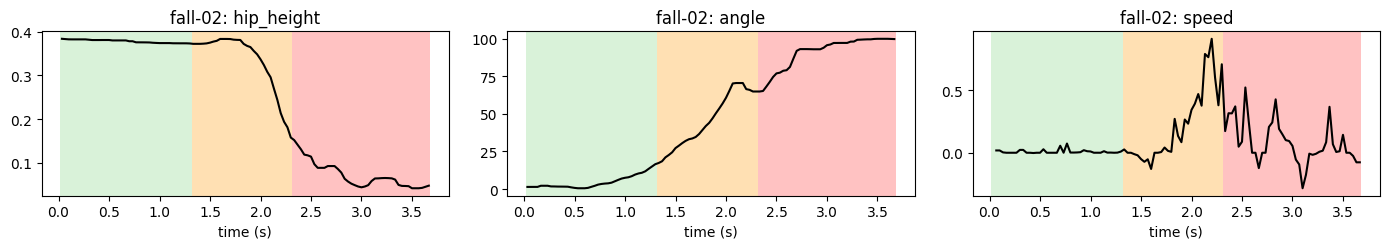

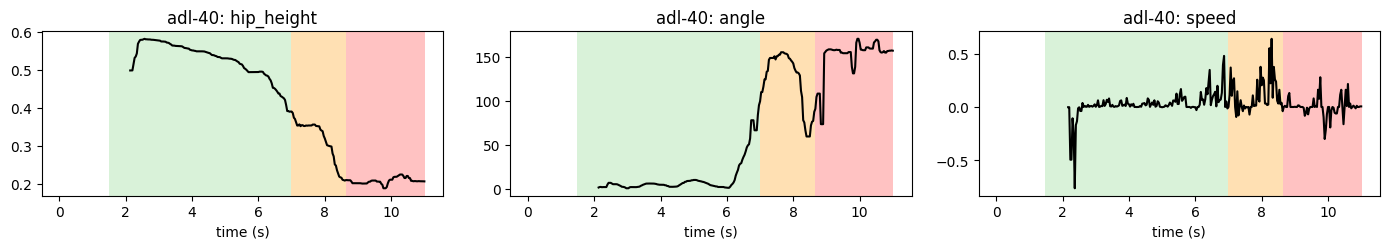

In [3]:
COLORS = {"not lying": "#d9f2d9", "falling": "#ffe0b3", "lying": "#ffc2c2", "no label": "white"}

def plot_signals(video):
    d = skel[skel.video == video]
    t = d.frame / 30
    fig, axes = plt.subplots(1, 3, figsize=(14, 2.6))
    for ax, col in zip(axes, ["hip_height", "angle", "speed"]):
        for (_, row) in d.iterrows():
            ax.axvspan(row.frame / 30 - 1/60, row.frame / 30 + 1/60, color=COLORS[row.phase], lw=0)
        ax.plot(t, d[col], color="black")
        ax.set(title=f"{video}: {col}", xlabel="time (s)")
    plt.tight_layout(); plt.show()

plot_signals("fall-02")
plot_signals("adl-40")

💡 **Interpretation:** in `fall-02` the hips drop from 0.38 to 0.15 in **about 0.7 s** (speed peak ≈ 0.9) while the body turns flat (0° → 100°).
In `adl-40` the person also ends lying, but the hips go down **slowly, over about 6 s**: same end position, different *speed*, and that is what the rules will use.

## Step 3 — Choosing the thresholds

Each rule needs a number (a *threshold*). We take them from the data:
- **fast drop:** for each video, the fastest hip drop. Falls should be clearly faster than daily activities;
- **lying:** from the table of Step 1, lying frames have a body angle around 80–90° and hips near the bottom of the image.

      count  mean   std  min   25%   50%   75%   max
kind                                                
adl    40.0  0.57  0.26  0.1  0.37  0.56  0.68  1.58
fall   30.0  1.09  0.34  0.6  0.84  1.07  1.30  1.89


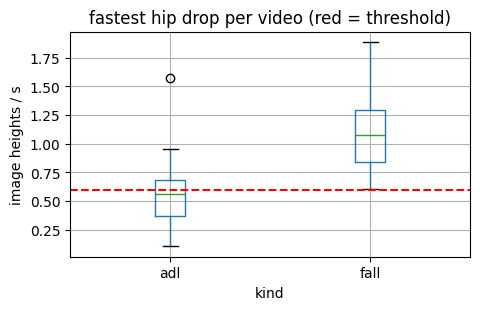

In [4]:
fastest = skel.groupby("video").speed.max().to_frame("fastest_drop")
fastest["kind"] = np.where(fastest.index.str.startswith("fall"), "fall", "adl")
print(fastest.groupby("kind").fastest_drop.describe().round(2))

fastest.boxplot(column="fastest_drop", by="kind", figsize=(5, 3))
plt.axhline(0.6, color="red", ls="--"); plt.suptitle(""); plt.title("fastest hip drop per video (red = threshold)")
plt.ylabel("image heights / s"); plt.show()

💡 **Interpretation:** every fall has a fastest drop of at least **0.60**, while half of the ADLs stay below 0.56. The boxes still overlap (one ADL reaches 1.58),
so speed alone is not enough: the rules also require lying **after** the drop.

Our thresholds:

| Rule | Value | In words |
|---|---|---|
| `SPEED_FALL` | 0.6 | the hips drop faster than 60% of the image height per second |
| `ANGLE_FLAT` | 60° | the body is closer to horizontal than to vertical |
| `HIP_LOW` | 0.2 | the hips are in the lowest 20% of the image |
| `MAX_FALL_TIME` | 45 frames (1.5 s) | after a fast drop, the person must reach the floor within 1.5 s |
| `MIN_LIE_TIME` | 10 frames (⅓ s) | still lying ⅓ s later → fall detected |

**Lying = body flat OR hips low.** We use *or* because the skeleton is often wrong on the floor (notebook 09): when one signal fails, the other can still see it.
`MIN_LIE_TIME` is short because many fall videos **stop less than 1 second** after the person reaches the floor.

## Step 4 — The state machine

The code reads the video frame by frame. When the person is **not found** (`missing`), it simply stays in its current state: no information means no change.

In [5]:
SPEED_FALL, ANGLE_FLAT, HIP_LOW = 0.6, 60, 0.2
MAX_FALL_TIME, MIN_LIE_TIME = 45, 10

def state_machine(d, speed_fall=SPEED_FALL):
    state, timer, states = "NORMAL", 0, []
    for height, angle, speed in zip(d.hip_height, d.angle, d.speed):
        missing = np.isnan(height) or np.isnan(angle)
        lying = not missing and (angle > ANGLE_FLAT or height < HIP_LOW)

        if state == "NORMAL":
            if not missing and speed > speed_fall:
                state, timer = "FALLING", 0
        elif state == "FALLING":
            timer += 1
            if lying:
                state, timer = "LYING", 0
            elif timer > MAX_FALL_TIME:          # dropped fast but never reached the floor
                state = "NORMAL"
        elif state == "LYING":
            timer += 1
            if not missing and not lying:        # got up again
                state = "NORMAL"
            elif timer >= MIN_LIE_TIME:
                state = "FALL DETECTED"
        # FALL DETECTED is final: the alarm stays on
        states.append(state)
    return states

skel["state"] = np.concatenate([state_machine(d) for _, d in skel.groupby("video", sort=False)])

d = skel[skel.video == "fall-02"]
print(d.groupby("state", sort=False).frame.agg(["min", "max"]).rename(columns={"min": "first frame", "max": "last frame"}))
print("first frame labelled 'lying':", d[d.phase == "lying"].frame.min())

               first frame  last frame
state                                 
NORMAL                   1          63
FALLING                 64          64
LYING                   65          74
FALL DETECTED           75         110
first frame labelled 'lying': 70


💡 **Interpretation:** on `fall-02` the machine follows the story: NORMAL until frame 63, a fast drop at 64, LYING from 65, and **FALL DETECTED at frame 75**,
only 5 frames (0.17 s) after the first frame the dataset labels *lying* (70).

## Step 5 — All 70 videos: fall or no fall?

A video is called a **fall** if the state machine ever reaches FALL DETECTED. We use the same measures as in notebook 02.
No training happens here, so there is **no cross-validation**: the rules are simply applied to every video.

accuracy : 0.914
recall   : 1.000
precision: 0.833


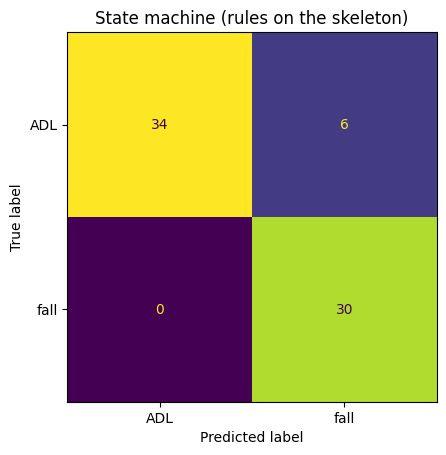

In [6]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, ConfusionMatrixDisplay

videos = skel.groupby("video").state.apply(lambda s: (s == "FALL DETECTED").any()).to_frame("detected")
y = videos.index.str.startswith("fall").astype(int)
pred = videos.detected.astype(int)

print(f"accuracy : {accuracy_score(y, pred):.3f}")
print(f"recall   : {recall_score(y, pred):.3f}")
print(f"precision: {precision_score(y, pred):.3f}")
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=["ADL", "fall"], colorbar=False)
plt.title("State machine (rules on the skeleton)"); plt.show()

💡 **Interpretation:** **all 30 falls are caught** (recall 1.000) with **6 false alarms** (precision 0.833), accuracy 0.914: a bit below the baseline (0.957),
but with **no training at all** and only an ordinary RGB camera (the baseline needs a depth camera).

## Step 6 — The false alarms

Which daily activities raised an alarm, and why? For each one: the fastest hip drop, and the body angle and hip height at the moment of the alarm.

In [7]:
alarms = videos.index[(pred == 1) & (y == 0)]
rows = []
for v in alarms:
    d = skel[skel.video == v]
    first = d[d.state == "FALL DETECTED"].iloc[0]
    rows.append({"video": v, "fastest_drop": d.speed.max(), "alarm_frame": first.frame, "of_frames": len(d),
                 "angle": first.angle, "hip_height": first.hip_height,
                 "lying_label_frames": (d.phase == "lying").sum()})
pd.DataFrame(rows).round(2)

,video,fastest_drop,alarm_frame,of_frames,angle,hip_height,lying_label_frames
0,adl-30,0.65,224,400,47.33,0.17,181
1,adl-31,0.78,107,250,24.56,0.19,76
2,adl-32,0.65,163,200,91.28,0.11,78
3,adl-33,0.68,112,200,81.44,0.17,65
4,adl-35,0.89,76,280,7.84,0.16,108
5,adl-39,0.74,172,270,179.29,0.34,77


💡 **Interpretation:** all 6 alarms are activities where the person **really goes down to the floor fairly fast** (fastest drop 0.65–0.89, just above 0.6) and stays there: for the rules this *is* a fall.
16 ADLs contain lying; the other 10 (including `adl-40`, which fooled the baseline) lie down slowly and raise no alarm.

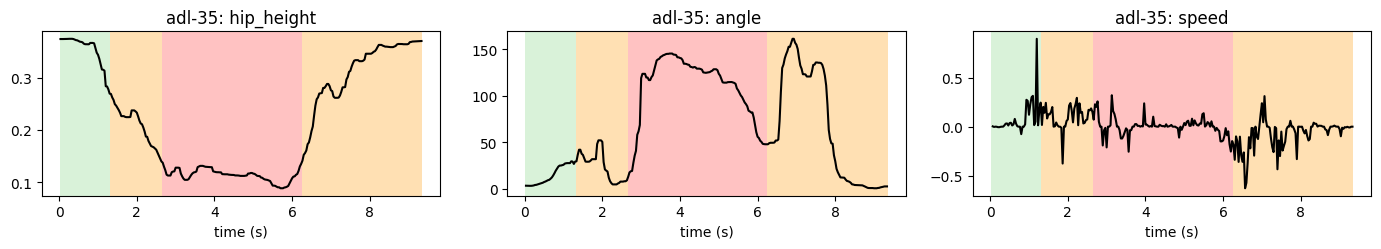

In [8]:
plot_signals("adl-35")

💡 **Interpretation:** in `adl-35` the person **kneels quickly** (one speed spike ≈ 0.9 at 1.2 s), crawls and lies on the floor on purpose, then gets up at ≈ 6.5 s.
Without knowing the *intention*, the movement matches a fall; and since FALL DETECTED is final, getting up does not cancel the alarm.

## Step 7 — How fast is the alarm?

For a real system, catching the fall is not enough: help must come **quickly**. For each fall video we compare the alarm time with the first frame labelled *lying*.

In [9]:
delays = []
for v, d in skel[skel.video.str.startswith("fall")].groupby("video"):
    alarm = d[d.state == "FALL DETECTED"].frame.min()
    on_floor = d[d.phase == "lying"].frame.min()
    delays.append((alarm - on_floor) / 30)
delays = pd.Series(delays)
print(f"alarm comes {delays.median():.2f} s after the person is on the floor (median)")
print(f"earliest {delays.min():.2f} s, latest {delays.max():.2f} s")

alarm comes 0.13 s after the person is on the floor (median)
earliest -0.07 s, latest 0.33 s


💡 **Interpretation:** the alarm comes **0.13 s** after the person reaches the floor (median, at most 0.33 s): almost immediate.
A negative value (−0.07 s) means the alarm came just before the label switched to *lying*, at the very end of the fall.

## Step 8 — Do the results depend on the exact threshold?

We chose `SPEED_FALL = 0.6` by looking at the data, and we test on the same videos, so the score is a bit **optimistic**. A good sign is when nearby values give similar results; a bad sign is when the score collapses as soon as the number moves.

In [10]:
rows = []
for sp in [0.4, 0.5, 0.6, 0.7, 0.8]:
    det = np.array([("FALL DETECTED" in state_machine(d, speed_fall=sp)) for _, d in skel.groupby("video")])
    rows.append({"SPEED_FALL": sp, "falls caught (/30)": det[y == 1].sum(), "false alarms (/40)": det[y == 0].sum(),
                 "accuracy": round((det == y).mean(), 3)})
pd.DataFrame(rows)

,SPEED_FALL,falls caught (/30),false alarms (/40),accuracy
0,0.4,30,10,0.857
1,0.5,30,7,0.900
2,0.6,30,6,0.914
3,0.7,26,3,0.900
4,0.8,24,1,0.900


💡 **Interpretation:** a lower threshold adds false alarms (10 at 0.4), a higher one misses falls (24/30 at 0.8): the classic **trade-off** between missed falls and false alarms.
Between 0.5 and 0.7 the accuracy stays at 0.90–0.91, so our choice is not fragile.

## What we learned

1. **Simple rules already work:** 30 of 30 falls caught, 6 false alarms (accuracy 0.914), alarm about 0.13 s after reaching the floor, with no training and no depth camera.
2. **The order of events is the key idea:** *fast drop → lying → stays down*. Lying down **slowly** (10 of the 16 ADLs with lying, including `adl-40`) is correctly ignored.
3. **Limits (for the report):**
   - going down to the floor **quickly on purpose** (kneeling, crawling) looks exactly like a fall: rules cannot see intention;
   - the thresholds were chosen by looking at these same videos, so the score is a bit optimistic (Step 8 shows it is stable, though);
   - "hips low" depends on where the camera is placed; a new room would need new thresholds;
   - the fall is confirmed after only ⅓ s because the videos stop soon after the fall; a real system would wait longer (e.g. several seconds without getting up) to cut false alarms like `adl-35`.

**Next notebook (11):** deep learning on the images: pretrained CNNs (MobileNet, ResNet) fine-tuned on the person crops.